# Etapa 7 — Janelas móveis

Para cada janela de N meses (deslizando 1 mês por vez):
1. **VAR(1)** com a mesma ordenação da etapa 6 → FEVD do câmbio em h = 12 → peso externo, doméstico e próprio.
2. **Checagem**: regressão limpa da etapa 5 na mesma janela → R² externo e doméstico.

- Janela principal: **60 meses**; robustez: **84 meses**.
- Cada resultado é datado no **fim da janela** ("peso nos N meses até esta data").

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.api import VAR

dados = pd.read_csv("../dados/tratados/variacoes_mensais.csv", index_col=0, parse_dates=True).asfreq("ME")

EXTERNAS = ["d_ust10", "dl_vix", "dl_dolar"]
DOMESTICAS = ["d_selic", "d_primario", "dl_cds"]
ORDEM = EXTERNAS + DOMESTICAS + ["dl_cambio"]
P = 1     # defasagens, fixo em todas as janelas
H = 12    # horizonte da FEVD

## 1. O que é calculado em cada janela

Duas funções que recebem o pedaço dos dados de uma janela e devolvem os pesos.
São exatamente os cálculos das etapas 6 e 5, só que aplicados a um pedaço da amostra.

In [2]:
def pesos_var(janela):
    """FEVD do câmbio (h = H) agregada por bloco, como na etapa 6."""
    decomp = VAR(janela[ORDEM]).fit(P).fevd(H).decomp[-1][H - 1]   # câmbio é a última variável
    contrib = pd.Series(decomp, index=ORDEM)
    return {
        "externo": contrib[EXTERNAS].sum(),
        "doméstico": contrib[DOMESTICAS].sum(),
        "próprio": contrib["dl_cambio"],
    }


def pesos_regressao(janela):
    """R² externo e doméstico (limpo) dentro da janela, como na etapa 5."""
    X_ext = sm.add_constant(janela[EXTERNAS])
    dom_limpas = pd.DataFrame({d: sm.OLS(janela[d], X_ext).fit().resid for d in DOMESTICAS})
    r2_ext = sm.OLS(janela["dl_cambio"], X_ext).fit().rsquared
    r2_dom = sm.OLS(janela["dl_cambio"], sm.add_constant(dom_limpas)).fit().rsquared
    return {"externo": r2_ext, "doméstico": r2_dom}

## 2. Deslizando a janela

`dados.iloc[i : i + N]` = N meses a partir da posição *i*. O resultado é guardado com a data do
último mês da janela.

In [3]:
def rolar(N, funcao):
    resultados = {}
    for i in range(len(dados) - N + 1):
        janela = dados.iloc[i : i + N]
        resultados[janela.index[-1]] = funcao(janela)
    saida = pd.DataFrame(resultados).T
    saida["externo / explicado"] = saida["externo"] / (saida["externo"] + saida["doméstico"])
    return saida

var60 = rolar(60, pesos_var)
var84 = rolar(84, pesos_var)
reg60 = rolar(60, pesos_regressao)

print(f"Janelas de 60 meses: {len(var60)}  ({var60.index[0]:%m/%Y} → {var60.index[-1]:%m/%Y})")
print(f"Janelas de 84 meses: {len(var84)}  ({var84.index[0]:%m/%Y} → {var84.index[-1]:%m/%Y})")

Janelas de 60 meses: 155  (12/2013 → 10/2026)
Janelas de 84 meses: 131  (12/2015 → 10/2026)


## 3. Composição do erro de previsão do câmbio ao longo do tempo (VAR, 60 meses)

Cada ponto do eixo x = **fim** de uma janela de 5 anos.

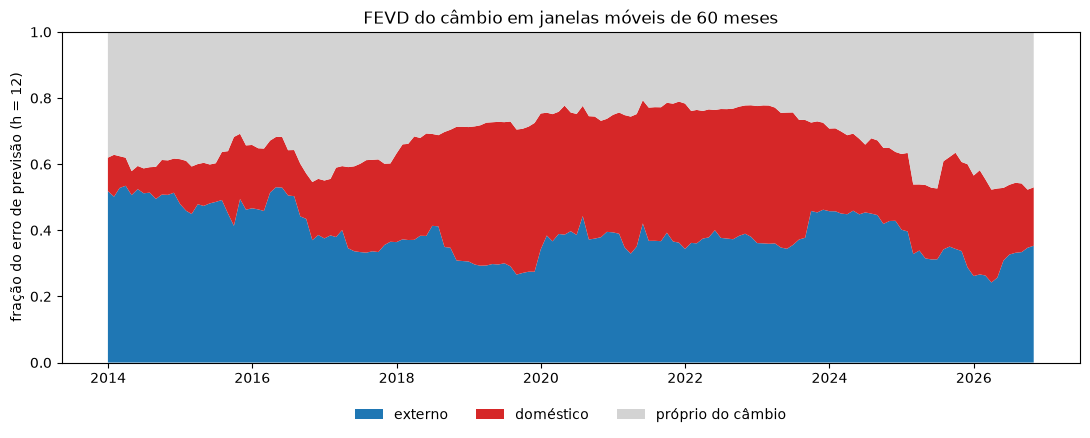

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.stackplot(var60.index, var60["externo"], var60["doméstico"], var60["próprio"],
             labels=["externo", "doméstico", "próprio do câmbio"],
             colors=["tab:blue", "tab:red", "lightgray"])
ax.set_ylim(0, 1)
ax.set_ylabel("fração do erro de previsão (h = 12)")
ax.set_title("FEVD do câmbio em janelas móveis de 60 meses")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

## 4. Peso externo dentro do que é explicado — três estimativas

- **VAR 60m** (principal), **VAR 84m** (robustez: janela maior), **Regressão 60m** (checagem: outro método).
- Linhas verticais = episódios. Lembre: com o carimbo no fim, um episódio **entra** na janela quando
  acontece e **sai** 60 meses depois (84 na janela longa).

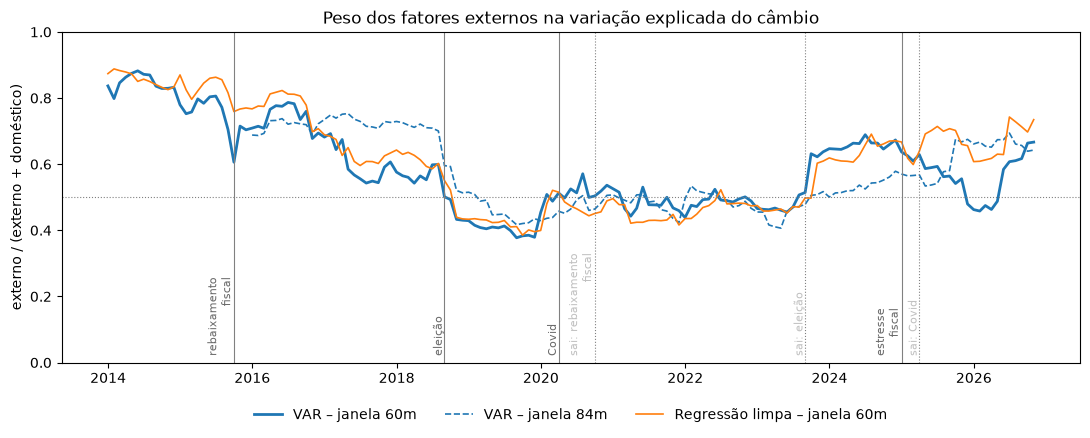

In [5]:
episodios = {
    "2015-09-30": "rebaixamento\nfiscal",
    "2018-08-31": "eleição",
    "2020-03-31": "Covid",
    "2024-12-31": "estresse\nfiscal",
}

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(var60.index, var60["externo / explicado"], color="tab:blue", lw=2, label="VAR – janela 60m")
ax.plot(var84.index, var84["externo / explicado"], color="tab:blue", lw=1.2, ls="--", label="VAR – janela 84m")
ax.plot(reg60.index, reg60["externo / explicado"], color="tab:orange", lw=1.2, label="Regressão limpa – janela 60m")
ax.axhline(0.5, color="gray", lw=0.8, ls=":")
for data, nome in episodios.items():
    entrada = pd.Timestamp(data)
    saida = entrada + pd.DateOffset(months=60)   # quando o episódio deixa a janela de 60 meses
    ax.axvline(entrada, color="gray", lw=0.8)
    ax.text(entrada, 0.02, nome, fontsize=8, rotation=90, va="bottom", ha="right", color="dimgray")
    if saida <= var60.index[-1]:
        ax.axvline(saida, color="gray", lw=0.8, ls=":")
        ax.text(saida, 0.02, f"sai: {nome}", fontsize=8, rotation=90, va="bottom", ha="right", color="silver")
ax.set_ylim(0, 1)
ax.set_ylabel("externo / (externo + doméstico)")
ax.set_title("Peso dos fatores externos na variação explicada do câmbio")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

## 5. Números

Resumo de cada estimativa e um retrato no fim de cada ano (janela de 60 meses).

In [6]:
def resumo(serie):
    return {"média": serie.mean(), "mínimo": serie.min(), "quando (mín.)": f"{serie.idxmin():%m/%Y}",
            "máximo": serie.max(), "quando (máx.)": f"{serie.idxmax():%m/%Y}"}

pd.DataFrame({
    "VAR 60m": resumo(var60["externo / explicado"]),
    "VAR 84m": resumo(var84["externo / explicado"]),
    "Regressão 60m": resumo(reg60["externo / explicado"]),
}).T

,média,mínimo,quando (mín.),máximo,quando (máx.)
VAR 60m,0.589795,0.377404,08/2019,0.882304,05/2014
VAR 84m,0.567701,0.406499,04/2023,0.752984,04/2017
Regressão 60m,0.610389,0.385432,09/2019,0.888148,01/2014


In [7]:
# Correlação entre as estimativas (nas datas em comum): andam juntas?
comuns = pd.concat({"VAR 60m": var60["externo / explicado"], "VAR 84m": var84["externo / explicado"],
                    "Regressão 60m": reg60["externo / explicado"]}, axis=1).dropna()
comuns.corr().round(2)

,VAR 60m,VAR 84m,Regressão 60m
VAR 60m,1.00,0.63,0.87
VAR 84m,0.63,1.00,0.79
Regressão 60m,0.87,0.79,1.00


In [8]:
retrato = var60[var60.index.month == 12][["externo", "doméstico", "próprio", "externo / explicado"]]
retrato.index = [f"{d:%Y} (janela {d.year - 4}–{d.year})" for d in retrato.index]
retrato.round(2)

,externo,doméstico,próprio,externo / explicado
2013 (janela 2009–2013),0.52,0.10,0.38,0.84
2014 (janela 2010–2014),0.48,0.14,0.38,0.78
2015 (janela 2011–2015),0.47,0.19,0.34,0.71
2016 (janela 2012–2016),0.38,0.18,0.45,0.68
2017 (janela 2013–2017),0.36,0.27,0.37,0.58
2018 (janela 2014–2018),0.31,0.41,0.29,0.43
2019 (janela 2015–2019),0.34,0.41,0.25,0.45
2020 (janela 2016–2020),0.39,0.36,0.25,0.53
2021 (janela 2017–2021),0.34,0.44,0.22,0.44
2022 (janela 2018–2022),0.36,0.41,0.22,0.47


In [9]:
var60.to_csv("resultados/etapa7_var_janela60.csv")
var84.to_csv("resultados/etapa7_var_janela84.csv")
reg60.to_csv("resultados/etapa7_regressao_janela60.csv")